In [1]:
%%capture
# ── Install required libraries ───────────────────────────────────────
# `datasets`     → HuggingFace dataset loader (for the SHAP sentiment example)
# `transformers` → HuggingFace BERT model + tokenizer
# `seaborn`      → prettier plots (optional but nice for tutorials)
# `shap`         → SHapley Additive exPlanations (one of the two methods)
# `lime`         → Local Interpretable Model-agnostic Explanations
!pip install datasets
!pip install transformers
!pip install seaborn
!pip install shap
!pip install lime

# ── Data / numerics / plotting ───────────────────────────────────────
import datasets
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ── HuggingFace transformers (used for the SHAP BERT example) ────────
import transformers

# ── SHAP and supporting sklearn text vectorizers ─────────────────────
import shap
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# ── LIME and its submodular-pick variant (SP-LIME) ───────────────────
import lime
from lime.lime_text import LimeTextExplainer
from lime import submodular_pick

ImportError: cannot import name '_center' from 'numpy._core.umath' (/Users/schiba/Projects/zhaw-bachelor/venv/lib/python3.12/site-packages/numpy/_core/umath.py)

# Explainable AI Tutorial

Explailable AI (XAI) aims to enhance transparency of (complex) AI models by clarifying the reasoning behind their predictions, which is crucial for their practical use and widespread adoption, particularly in high-stakes applications (healthcare, legal).

Below we show and look into the details of several examples.

## Inherently interpretable models

Inherently interpretable models are transparent by design.

These models, such as decision trees, linear models, and rule-based systems, make their decision-making process directly visible through simple structures that humans can easily inspect and understand.
Unlike complex neural networks that require additional explanation tools, interpretable models show their logic explicitly: you can trace exactly how each feature contributes to a prediction.

This transparency is particularly valuable in high-stakes applications like healthcare and finance, where understanding why a model made a specific prediction is just as critical as the prediction itself.

We will showcase the decision tree approach on the task of predicting whether breast cancer is malignant or benign using the public breast cancer dataset.


In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
# Load data
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
feature_names = X.columns
target_names = data.target_names

print(X.head(3))

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38           122.8     1001.0          0.11840   
1        20.57         17.77           132.9     1326.0          0.08474   
2        19.69         21.25           130.0     1203.0          0.10960   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0                 0.07871  ...         25.38          17.33            184.6   
1                 0.05667  ...         24.99          23.41            158.8   
2                 0.05999  ...         23.57          25.53            152.5   

   worst area  worst smoothness  worst compactness  worst concavity  \
0 

In [4]:
# Split data into training and test stratifying on the class
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Train decision tree classifier model
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [5]:
# Inference on the test set and model evaluation
y_pred = tree.predict(X_test)
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=target_names))

Classification Report:

              precision    recall  f1-score   support

   malignant       0.90      0.89      0.90        64
      benign       0.94      0.94      0.94       107

    accuracy                           0.92       171
   macro avg       0.92      0.92      0.92       171
weighted avg       0.92      0.92      0.92       171



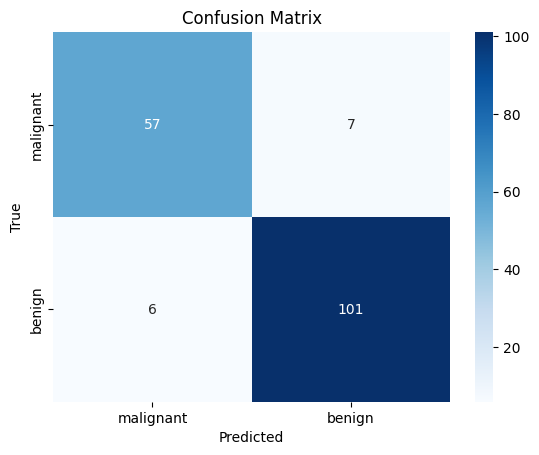

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

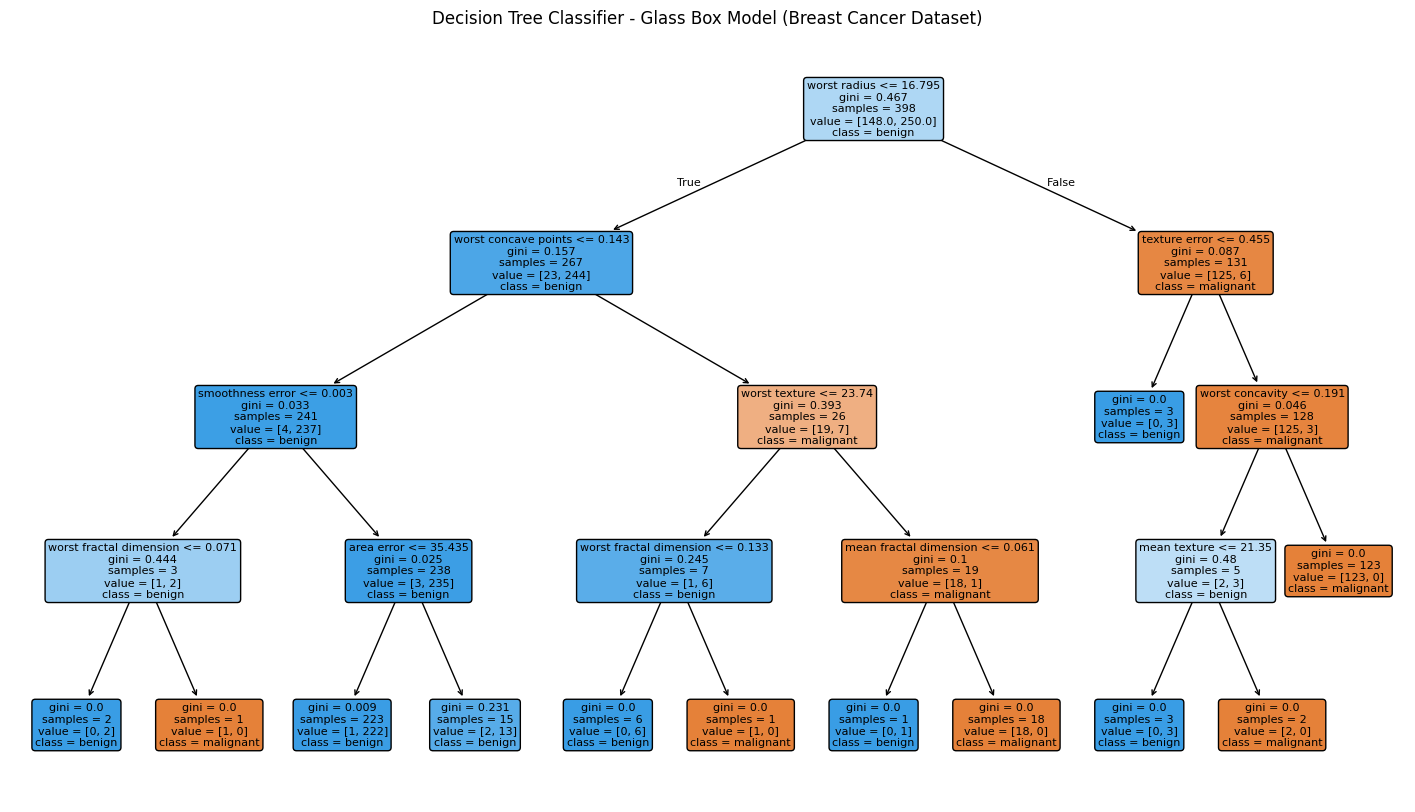

In [7]:
# Visualize the trained decision tree model
plt.figure(figsize=(18, 10))
plot_tree(tree, filled=True, rounded=True,
          feature_names=feature_names,
          class_names=target_names,
          fontsize=8)
plt.title("Decision Tree Classifier - Glass Box Model (Breast Cancer Dataset)")
plt.show()

This tree shows the exact decision logic used by the model. Each node corresponds to a condition using a threshold (e.g., “mean radius ≤ 16.8”) that splits the data in two parts. Each path from the root of the tree to a leaf corresponds to a rule leading to a predicted diagnosis (benign or malignant) and provides a transparent rule-based decision.

This makes the model **transparent** and easy to audit. We can also see which features drive predictions.  
The model’s simplicity also helps detect potential **bias**, for example, if specific features dominate decisions or if thresholds align with measurement artifacts.  
Because all features are numerical, the decision boundaries are clear and easy to interpret visually.

We can also see the numerical values of importances for each of the features:

In [8]:
# Feature importances
importances = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nFeature Importances:")
display(importances.head(10))


Feature Importances:


,Feature,Importance
20,worst radius,0.733864
27,worst concave points,0.132649
21,worst texture,0.036691
11,texture error,0.030980
26,worst concavity,0.019168
29,worst fractal dimension,0.016887
1,mean texture,0.013298
9,mean fractal dimension,0.010499
14,smoothness error,0.003377
13,area error,0.002586


## XAI approaches for black-box models

When using black-box models for a target task, one way towards model explainability is using post-hoc interpretation XAI approaches. In this tutorial we focus on feature importance XAI approaches that aim to identify the most important features for the prediction of a complex AI model. By clarifying which features influence a model’s predictions, XAI allows users to verify the model’s reasoning, identify potential biases or errors, and make more informed decisions based on its outputs.

Various XAI feature importance approaches exist and they can be applied at different levels:

*   **Global explanations** help understand the overall behavior of a model across all inputs.
*   **Local explanations** focus on individual predictions, showing why the model made a specific decision for a single case.


In the following we look at two very popular ones, namely, `lime` and `shap`.
Both methods are model-agnostic, making them versatile tools to interpret black-box models such as deep neural networks and ensemble methods.

## LIME
The core principle of LIME is that even if an AI model behaves non-linearly across the entire input space, it can be approximated locally by a simpler, interpretable model. To explain a specific prediction, LIME perturbs the input data around the instance of interest and observes how these perturbations affect the model's output. It then fits an interpretable model to these perturbed samples, weighting them according to their proximity to the original instance.

This local surrogate model captures the decision boundary of the complex model in the neighborhood of the instance being explained, providing insights into which features contributed most to that particular prediction.

LIME provides **local explanations only** as it focuses on explaining individual predictions. It approximates a complex model locally around a single instance using a simpler interpretable model, such as a linear regression.

**SP-LIME (Submodular Pick LIME)** extends LIME with the capablity to provide more global understanding of the model's behaviour. SP-LIME applies a submodular optimization algorithm to select a small, diverse, and representative set of instances from the target dataset. By explaining these carefully chosen instances with LIME, SP-LIME provides a more comprehensive picture of model behaviour across different types of inputs.

SP-LIME balances two objectives:
* **Coverage**: the selected instances collectively cover as many important features as possible.
* **Non-redundancy**: the selected instances avoid repeating the same explanations, so each new instance adds new information.

This makes the set of SP-LIME explanations jointly more informative than a random subset of equal size, providing a global view of feature importances for the ML model.

### LIME example
We will now use `LIME` explainability for a Random Forest model trained on YouTube spam classifications. We first train a model on the labeled comments (spam or not) from videos by PSY, Shakira, LMFAO, and Katy Perry. Then we apply `LIME` and `SP-LIME` as a post-hoc explainability approaches, to obtain both local explanations for the feature importance of target samples and global feature importances through a selection of a diverse and representative instances for explanation, respectively.

### Model training
We train a `Random Forest Classifier` model to identify spam comments of youtube videos using a labelled dataset.

In [9]:
# ── Load the YouTube spam comments dataset ───────────────────────────
# Five CSV files (one per artist's channel). Each row is a comment with a
# CLASS label: 1 = spam, 0 = not spam.
psy     = pd.read_csv('https://raw.githubusercontent.com/JasminaZHAW/XAI/refs/heads/main/data/Youtube01-Psy.csv')
perry   = pd.read_csv('https://raw.githubusercontent.com/JasminaZHAW/XAI/refs/heads/main/data/Youtube02-KatyPerry.csv')
LMFAO   = pd.read_csv('https://raw.githubusercontent.com/JasminaZHAW/XAI/refs/heads/main/data/Youtube03-LMFAO.csv')
Eminem  = pd.read_csv('https://raw.githubusercontent.com/JasminaZHAW/XAI/refs/heads/main/data/Youtube04-Eminem.csv')
Shakira = pd.read_csv('https://raw.githubusercontent.com/JasminaZHAW/XAI/refs/heads/main/data/Youtube05-Shakira.csv')

# Stack them all into one DataFrame and reset the row index.
full_train = pd.concat([psy, perry, LMFAO, Shakira, Eminem]).reset_index().drop(columns=['index'])

In [10]:
# Peek at the first 3 rows — note the COMMENT_ID, AUTHOR, DATE, CONTENT, CLASS columns.
# Only CONTENT (the comment text) and CLASS (the label) matter for our model.
display(full_train.head(3))

,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1


In [11]:
# ── Imports for the spam classifier ──────────────────────────────────
from sklearn.model_selection  import train_test_split
from sklearn.ensemble         import RandomForestClassifier
from sklearn.metrics          import classification_report
from lime.lime_text           import LimeTextExplainer

# ── Inputs and labels ────────────────────────────────────────────────
X = full_train['CONTENT']        # the raw comment text
y = full_train['CLASS']          # 1 = spam, 0 = not spam

# ── Turn text into numeric features with TF-IDF ──────────────────────
# TF-IDF gives each word a weight that grows with how often it appears in a
# given comment, but shrinks if it also appears in many other comments.
# `stop_words="english"` drops uninformative words like "the", "is", "and".
tfidf    = TfidfVectorizer(ngram_range=(1, 1), stop_words="english")
features = tfidf.fit_transform(X)

# Convert the sparse matrix to a dense DataFrame so we can name columns
# (LIME's tabular flow benefits from feature names — we use it for inspection).
X_tfidf = pd.DataFrame(features.todense(), columns=tfidf.get_feature_names_out())

# ── Train / test split (70 / 30) ─────────────────────────────────────
# We split twice: once for the RAW text (used by LIME) and once for the
# TF-IDF matrix (used by the classifier). Both splits use the same random
# state so the rows correspond.
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=13
)
X_train, X_test, _, _ = train_test_split(
    X_tfidf.fillna(0), y, test_size=0.3, stratify=y, random_state=13
)

# ── Random forest classifier (100 trees) ─────────────────────────────
rf_clf = RandomForestClassifier(max_features=2, n_estimators=100, bootstrap=True)
rf_clf.fit(X_train, y_train)


def predict_proba_text(texts):
    """
    LIME requires a function that takes a list of raw strings and returns
    a (n_samples, n_classes) probability matrix. We wrap TF-IDF + RF here.
    """
    text_tfidf = tfidf.transform(texts)
    text_df    = pd.DataFrame(text_tfidf.toarray(), columns=tfidf.get_feature_names_out())
    return rf_clf.predict_proba(text_df)


# ── Quick sanity check: how good is the model? ───────────────────────
y_pred = rf_clf.predict(X_test)
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.99      0.90      0.95       313
           1       0.90      0.99      0.94       274

    accuracy                           0.95       587
   macro avg       0.95      0.95      0.95       587
weighted avg       0.95      0.95      0.95       587



### Local Feature Importance
In order to visualize how LIME attributes importance to each feature for a specific instance,  we plot the feature importance weights below.  

We choose one spam and one non-spam sample from the test set and create a barplot that explains the feature importances for each, showing the weights (both positive and negative) of words impacting the explanation. This visualization shows which words (features) contributed most to the model classifying a comment as spam or non-spam.

In [12]:
# Silence a benign LIME warning that fires when our text pool is small
# (it just means LIME used all available samples instead of subsampling).
import warnings
warnings.filterwarnings('ignore', message='Requested sample size', category=UserWarning)

# ── LIME explainer for TEXT data ─────────────────────────────────────
# LIME perturbs the text by randomly removing words, asks the model for
# predictions on the perturbed versions, and fits a tiny linear model that
# locally approximates our random forest.
class_names   = ['Not spam', 'Spam']
feature_names = list(X_train.columns)            # the TF-IDF vocabulary

lime_text = LimeTextExplainer(class_names=class_names)


SPAM Comment: If interested in making extra money by internet use the next link www.swagbucks.com/refer/Nonturtle02﻿...

NOT SPAM Comment: the most viewed youtube video of all time?﻿...


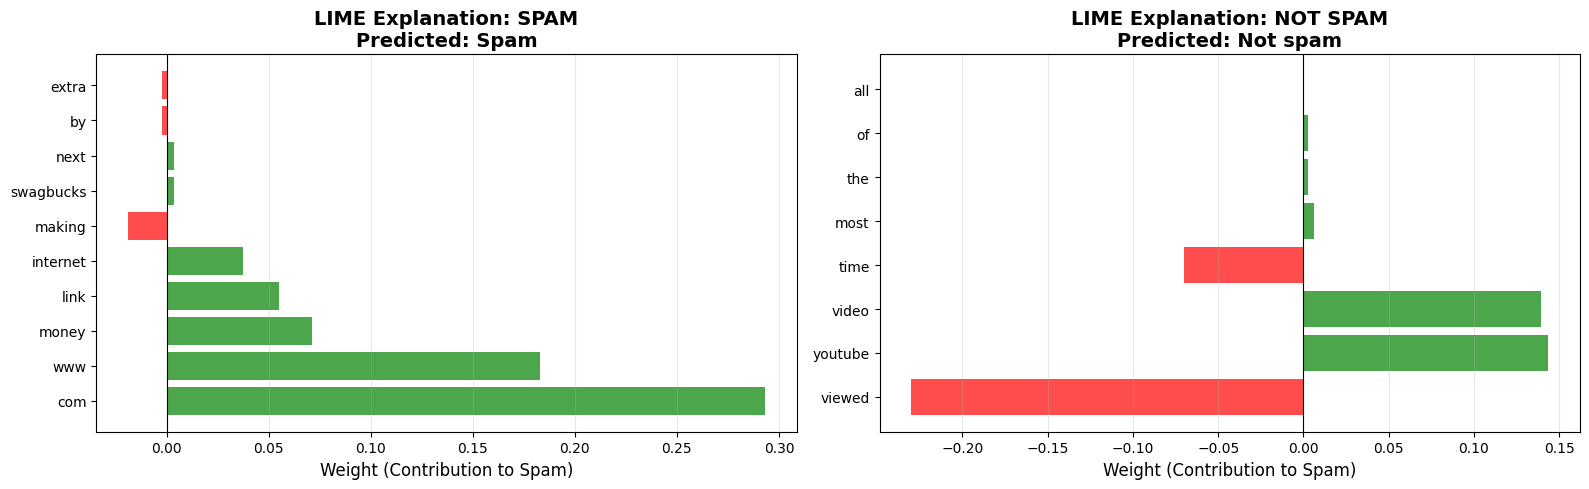

In [13]:
# ── Local explanation: one spam + one non-spam example ───────────────
# We pick one comment of each class from the test set and ask LIME which
# words pushed the model toward its decision.
spam_idx     = y_test[y_test == 1].index[0]
non_spam_idx = y_test[y_test == 0].index[0]

# Plot the top-10 contributing words for each, side by side.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for idx, (example_idx, label) in enumerate([(spam_idx, 'SPAM'),
                                            (non_spam_idx, 'NOT SPAM')]):
    text = X_test_text.loc[example_idx]

    # `explain_instance` builds the local surrogate and returns word weights.
    # `num_features=10` → keep only the 10 most influential words.
    exp = lime_text.explain_instance(text, predict_proba_text, num_features=10)

    feat_imp = exp.as_list()                      # [(word, weight), ...] sorted by |weight|
    words    = [f[0] for f in feat_imp]
    weights  = [f[1] for f in feat_imp]

    # Green = positive weight (pushes toward spam), red = negative (toward not-spam).
    colors = ['green' if w > 0 else 'red' for w in weights]
    axes[idx].barh(words, weights, color=colors, alpha=0.7)

    pred_class = np.argmax(exp.predict_proba)
    axes[idx].set_xlabel('Weight (Contribution to Spam)', fontsize=12)
    axes[idx].set_title(f'LIME Explanation: {label}\nPredicted: {class_names[pred_class]}',
                        fontsize=14, fontweight='bold')
    axes[idx].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    axes[idx].grid(axis='x', alpha=0.3)
    print(f"\n{label} Comment: {text[:200]}...")

plt.tight_layout()
plt.show()

### Feature importance across multiple samples
Next, we extend our analysis to understand global model behaviour.

SP-LIME uses submodular optimization to select a diverse, non-redundant set of representative instances from the test set. Rather than randomly sampling instances, SP-LIME actively chooses instances that together cover as many important features as possible, giving a more informative view of the model's overall behaviour.

We run SP-LIME on a pool of test samples and examine the feature importance distribution across the selected instances. We compute the average importance per feature and how frequently each feature appears across the selected SP-LIME explanations. This helps us understand which features consistently influence the model across different representative examples.

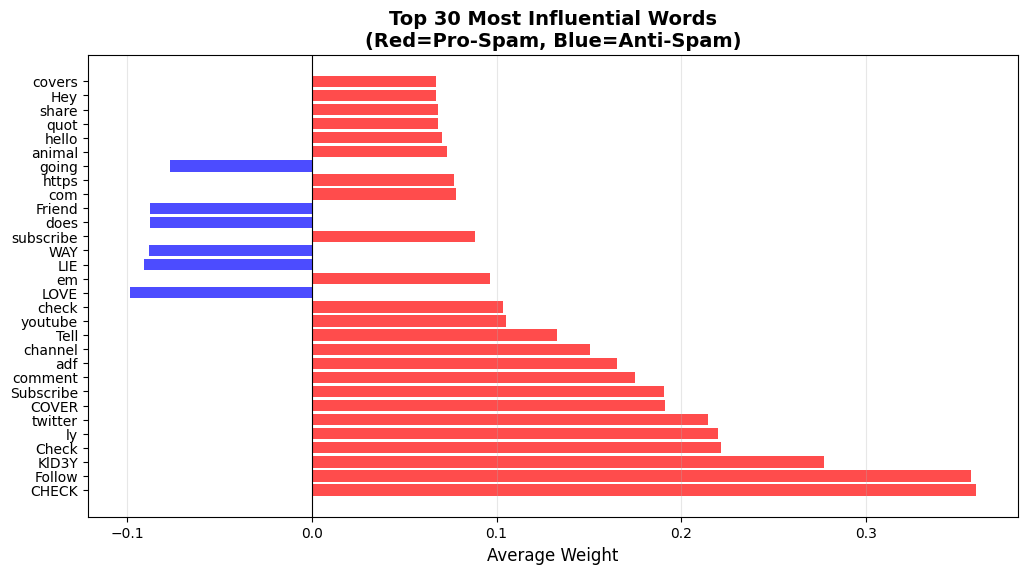

In [14]:
# ── SP-LIME: from local to (more) global explanations ────────────────
# Instead of inspecting random comments, SP-LIME PICKS comments whose
# explanations together cover as many important features as possible.
n_pool     = 100   # how many candidate comments SP-LIME will consider
n_selected = 20    # how many of those it will keep (the "submodular pick")

# Sample a random pool from the test set for SP-LIME to evaluate.
np.random.seed(42)
pool_indices = np.random.choice(len(X_test_text), n_pool, replace=False)
pool_texts   = list(X_test_text.iloc[pool_indices])

# Run SP-LIME — under the hood it:
#   1) runs LIME on every comment in the pool,
#   2) greedily selects a diverse subset that maximises feature coverage.
sp_multi = submodular_pick.SubmodularPick(
    lime_text, pool_texts, predict_proba_text,
    num_features=15, num_exps_desired=n_selected, top_labels=0
)

# ── Aggregate word importances across the selected explanations ─────
# For each word, collect every weight it received across the chosen comments.
word_importance = {}
for exp in sp_multi.sp_explanations:
    for word, weight in exp.as_list():
        word_importance.setdefault(word, []).append(weight)

# Summarise each word with mean / std / count of appearances.
word_stats = {
    word: {
        'mean' : np.mean(weights),
        'std'  : np.std(weights),
        'count': len(weights),
    }
    for word, weights in word_importance.items()
}

# Sort by absolute mean importance (largest effect, either direction).
sorted_words = sorted(word_stats.items(), key=lambda x: abs(x[1]['mean']), reverse=True)[:30]

# ── Plot: top 30 most influential words across the SP-LIME selection ─
plt.figure(figsize=(12, 6))
words  = [w[0] for w in sorted_words]
means  = [w[1]['mean'] for w in sorted_words]
colors = ['red' if m > 0 else 'blue' for m in means]    # red = spam, blue = not-spam

plt.barh(words, means, color=colors, alpha=0.7)
plt.xlabel('Average Weight', fontsize=12)
plt.title('Top 30 Most Influential Words\n(Red=Pro-Spam, Blue=Anti-Spam)',
          fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.grid(axis='x', alpha=0.3)
plt.show()

## SHAP (SHapley Additive exPlanations)

**SHAP** is a popular approach used for interpreting the output of machine learning models. It is based on the concept of Shapley values from cooperative game theory, which allocate the contribution of each feature to the model's predictions.

### How SHAP Works:
1. **Feature Contribution**: For each prediction, SHAP computes the contribution of each feature to the prediction by considering all possible feature combinations.
2. **Additive Feature Attribution**: The sum of SHAP values for all features equals the model’s prediction, ensuring consistency.


SHAP can provide both global and local explanations.



*   **Local**: For a single prediction, SHAP assigns a contribution value to each feature, showing exactly how it influenced that specific output.
*  **Global**: By aggregating SHAP values across many samples (e.g., averaging absolute contributions per feature), you can see which features are most important overall for the model.


### Example of a sentiment analisys model
Let's start with an example of `shap` over a `Sentiment Analisys` model.

For this example we will use a pretrained BERT model, and we will try to identify how each feature affects the final prediction.

In [15]:
%%capture
# ── Load the "emotion" sentiment dataset from HuggingFace ────────────
# 16k tweets labelled with one of 6 emotions:
# {0: sadness, 1: joy, 2: love, 3: anger, 4: fear, 5: surprise}.
# We'll let SHAP explain a pretrained classifier's predictions on this data.
dataset = datasets.load_dataset("dair-ai/emotion", split="train")
data    = pd.DataFrame({"text": dataset["text"], "emotion": dataset["label"]})

In [16]:
%%capture
# ── Load a pretrained BERT emotion classifier ────────────────────────
# `nateraw/bert-base-uncased-emotion` is fine-tuned on the same 6-class
# emotion dataset, so it should give meaningful predictions out of the box.
tokenizer = transformers.AutoTokenizer.from_pretrained(
    "nateraw/bert-base-uncased-emotion", use_fast=True
)
model = transformers.AutoModelForSequenceClassification.from_pretrained(
    "nateraw/bert-base-uncased-emotion"
).cuda()    # if this fails, switch the Colab runtime to T4 GPU, or drop .cuda()

# ── Wrap in a HuggingFace pipeline ───────────────────────────────────
# `top_k=None` makes the pipeline return scores for ALL 6 classes, not just
# the top one — SHAP needs every class to allocate contributions to each.
pred = transformers.pipeline(
    "text-classification",
    model     = model,
    tokenizer = tokenizer,
    device    = 0,           # GPU id; set to -1 to run on CPU
    top_k     = None,
)

In [17]:
# ── Build the SHAP explainer ─────────────────────────────────────────
# SHAP wraps the prediction pipeline and the tokenizer. For text models it
# uses the Partition explainer: it masks groups of tokens and tracks how
# every group's removal changes the prediction.
shap_explainer = shap.Explainer(pred, tokenizer)

In [18]:
# ── Compatibility patch for shap.plots.text() ────────────────────────
# Recent NumPy versions print floats as `np.float64(0.12)` instead of `0.12`,
# which leaks into SHAP's HTML output and breaks the colour rendering. We
# monkey-patch the renderer to strip those wrappers out.
import re
from IPython.display import display as _ipython_display, HTML
import shap

_orig_shap_text = shap.plots.text

def _patched_shap_text(shap_values, display=True, **kwargs):
    html = _orig_shap_text(shap_values, display=False, **kwargs)
    if html:
        html = re.sub(r'np\.float64\(([^)]+)\)', r'\1', html)
    if display:
        _ipython_display(HTML(html))
    else:
        return html

shap.plots.text = _patched_shap_text

In [19]:
# ── Explain one example sentence ─────────────────────────────────────
shap.initjs()                                # load SHAP's JavaScript visualiser
test_sample = ["I am happy to have followed the XAI lecture, and it is sad it is already over"]

# Calling the explainer kicks off the masked-tokens analysis. The returned
# `shap_values` object has shape (n_samples, n_tokens, n_classes).
shap_values = shap_explainer(test_sample)

# `shap.plots.text` shows the sentence with each token coloured by its
# contribution to the model's top predicted class.
shap.initjs()
shap.plots.text(shap_values[0])

In order to see how individual words contribute to the prediction for a specific emotion, we plot the SHAP text visualization below.  
This helps us understand which words increase or decrease the model's confidence for the each emotion class.

In [20]:
# ── Same sentence, broken down per emotion class ─────────────────────
# Slicing `[:, :, "<class>"]` selects the contributions toward THAT emotion.
# Words colored red push toward the class; words in blue push away.
shap.plots.text(shap_values[:, :, "anger"])
shap.plots.text(shap_values[:, :, "joy"])
shap.plots.text(shap_values[:, :, "love"])
shap.plots.text(shap_values[:, :, "fear"])
shap.plots.text(shap_values[:, :, "surprise"])
shap.plots.text(shap_values[:, :, "sadness"])

### Contribution of words to prediction
In order to see the weights of each word in a sentence for different emotionsa waterfall barplot that shows how each token contributes to pushing the prediction from the base value can be used. This visualization helps us see the positive or negative impact of individual tokens on the model’s final prediction.

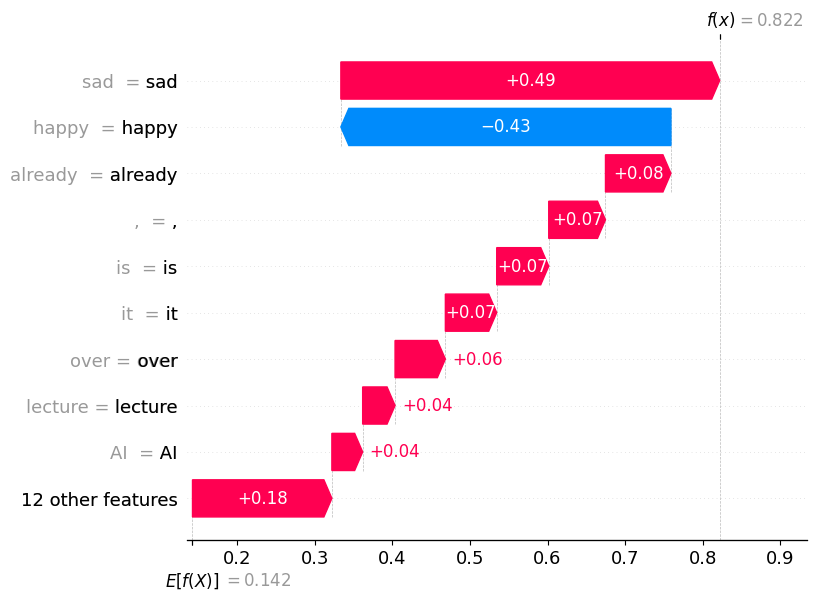

In [21]:
# ── Waterfall plot for the "sadness" class ───────────────────────────
# Waterfall plots are the canonical SHAP visualisation: they start from the
# model's BASE value (its average prediction) and add each token's
# contribution one at a time, ending at the final prediction.
shap.plots.waterfall(shap_values[0, :, "sadness"])

### Most important words across all emotions
To gain a broader perspective, we now visualize the most important words across *all* emotion classes.  
This aggregated view helps us identify common linguistic patterns and which words are generally influencing model predictions the most.

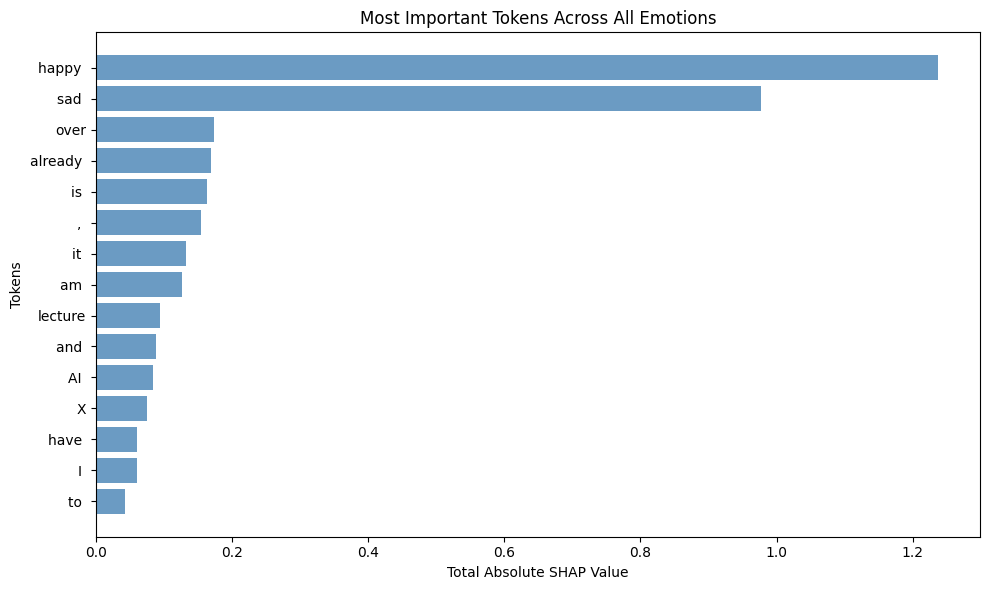

In [22]:
# ── Which tokens matter most ACROSS ALL emotions? ────────────────────
# Sum |SHAP value| across all 6 classes for each token: a token that strongly
# pushes either toward or away from any emotion ranks high here.
total_importance = np.abs(shap_values.values[0]).sum(axis=1)   # shape: (n_tokens,)
token_importance = dict(zip(shap_values.data[0], total_importance))

sorted_importance = sorted(token_importance.items(), key=lambda x: x[1], reverse=True)

# Plot the 15 most influential tokens.
plt.figure(figsize=(10, 6))
tokens_plot, values_plot = zip(*sorted_importance[:15])
plt.barh(tokens_plot, values_plot, color='steelblue', alpha=0.8)
plt.xlabel('Total Absolute SHAP Value')
plt.ylabel('Tokens')
plt.title('Most Important Tokens Across All Emotions')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Summary

LIME provides a local view of model behavior by approximating the decision boundary near a single instance. This localized explanation can be valuable for understanding why a particular prediction occurred, even if it differs from the model’s general trends.

SHAP provides a more consistent, theoretically grounded measure of feature impact based on game thepry.

Both methods complement each other: SHAP for understanding general patterns, and LIME for exploring local decision behavior in depth.

SP-LIME extends LIME by using submodular optimization to select a small, diverse, and representative set of instances from a given target dataset and provide insights into the global model behavior. Rather than explaining a single arbitrarily chosen instance, SP-LIME identifies which instances are collectively most informative — covering different parts of the feature space while avoiding redundancy. This bridges the gap between purely local explanations and a more global understanding of the model's behaviour.

By aggregating SHAP values across many samples, one can obtain global model explanations.



